# Sound Classification using Deep Learning


![uc3m](http://materplat.org/wp-content/uploads/LogoUC3M.jpg)
#### Mount Google Drive


In [1]:
# Load the Drive helper and mount
from google.colab import drive

# This will prompt for authorization.
drive.mount('/content/drive')

# Create a new folder in your drive and change to that directory as:
# /content/drive/My_Drive/new_dir_that_you_just_created_for_this_lab
import os
os.chdir('/content/drive/MyDrive/ATVAIV/LabSession2')

Mounted at /content/drive


#### Required Python libraries for the lab session
You may need to install librosa using pip as follows:
!pip install librosa==0.8.0


In [2]:
import os
import sys
import pickle
import copy

from datetime import datetime
from tqdm import tqdm

import librosa
import librosa.display
import numpy as np
import pandas as pd

import torch
import torch.nn.functional as F
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

import IPython.display as ipd
import matplotlib.pyplot as plt
%matplotlib inline

## [!] INSTRUCTIONS FOR THE SUBMISSION OF THE LAB EXERCISES

The objective of this activity is that the student strengthens the concepts about Sound Classification using CNNs and LSTMs.

In order to do the lab session exercises, the student has to use Google Colab, execute this notebook for its resolution and answer several brief questions, including both extra code and text cells, if necessary.

**This notebook with the solutions to the lab exercises must be submitted to Aula Global before the 20th November at 23:59h.**


# LAB SESSION 2
---

# Sound Classificaton with CNN-RNNs

### APPLICATIONS OF SPEECH, AUDIO, IMAGE AND VIDEO PROCESSING

### MASTER IN TELECOMMUNICATIONS ENGINEERING
### ACADEMIC COURSE 2026/2027

1. OBJECTIVE
2. DATABASE
3. READING AUDIO FILES AND FEATURE EXTRACTION
4. LOADING THE PRECOMPUTED FEATURES
5. DATA AUGMENTATION
6. UTILITY FUNCTIONS
7. CNN-RNN MODEL
8. SPLITTING AND NORMALIZING THE DATA
9. TRAINING AND TESTING THE SYSTEM

NOTE: you will find sections in this notebook called exercises, which are the ones you are expected to report for evaluation.

---
## 1. OBJECTIVE
---
The objective of this lab exercise is to implement an **environmental sound classification system based on Deep-Learning techniques**. This system takes and audio signal and provides the category to which it belongs.

The system is going to be implemented in **Pytorch** and uses log-mel spectrograms as input and **CNN-RNN** models. CNN-RNN consists of a combination of **Convolutional Neural Networks (CNNs)** and **Recursive Neural Networks (RNNs)**. In this lab, we are going to use a particular kind of RNNs, the **Long Short-Term Memory networks (LSTMs)**.

The main idea is that, as log-mel spectrograms are two dimensional signals, they can be visualized as images, so that CNNs are adequate for extraction more complex features from them. In addition, due to the sequential nature of log-mel spectrograms, LSTMs are suitable for performing a further processing prior to the classification itself.  

For building and assessing the system we are going to use urban sound excerpts from the **UrbanSound8K dataset**.

In this script, it is assumed that the audio database has been downloaded and the corresponding features have been generated in advance (see the script *LabSession2 - Sound Classfication - Preprocessing.ipynb* in Aula Global).



---
## 2. DATABASE
---
The database used in this lab session is the [UrbanSound8k dataset](https://urbansounddataset.weebly.com/urbansound8k.html) that contains 8732 labeled sound excerpts (<=4s) of urban sounds from 10 classes:

* air_conditioner
* car_horn
* children_playing
* dog_bark
* drilling
* enginge_idling
* gun_shot
* jackhammer
* siren
* street_music

This audio dataset is located in the directory *UrbanSound8K/audio/*.


---
## 3. READING AUDIO FILES AND FEATURE EXTRACTION
---

The following code shows an example of reading an audio file with the function **load** from the *librosa* library. Note that the sampling frequency of the audio file is 22050 Hz.

Sampling rate = 22050 Hz
Length of the audio signal = 66150 samples


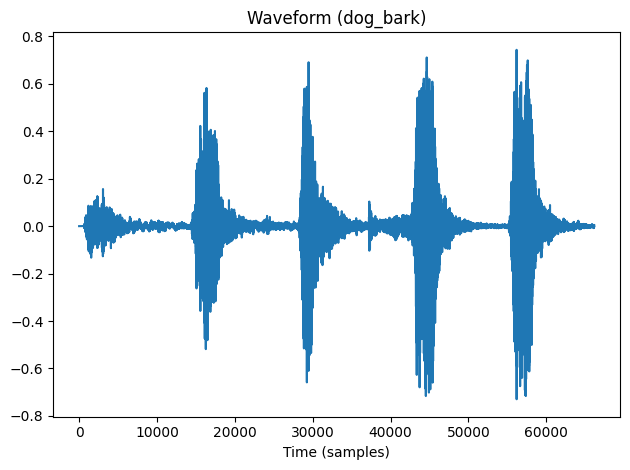

In [3]:
# READING AUDIO FILES

# Reading an audio file from the database
SOUND_DURATION = 3.0    # fixed duration of an audio excerpt in seconds

audio_file = 'UrbanSound8K/audio/fold2/100652-3-0-0.wav';
audio, sampling_rate = librosa.load(audio_file, duration=SOUND_DURATION)
print('Sampling rate =', sampling_rate, 'Hz')
print('Length of the audio signal =', len(audio), 'samples')

# Plot the audio signal. It corresponds to the category 'dog_bark'
fig, ax = plt.subplots()
plt.plot(audio)
plt.title('Waveform (dog_bark)')
ax.set_xlabel('Time (samples)')
plt.tight_layout()
plt.show()

# Play the audio data
ipd.Audio(audio, rate=sampling_rate)

The following code computes the log-mel spectrogram of the previous audio file considering the following configuration:

* Frame period or hop length = 512 samples (512 / 22050 = 23.25 ms)
* Size (length) of the analysis window = 1024 samples (1024 / 22050 = 46.5 ms)
* Number of filters in the mel filterbank = 128

For the log-mel spectrogram computation, we have used the function **melspectrogram** from the module *feature* of the *librosa* package. This function has, among others, the following input arguments:

* y: speech signal
* sr: sampling frequency
* hop_length: frame period or hop length (in samples)
* win_length: window size (in samples)
* n_mels: number of filters in the mel filterbank

Note that in this function the window size and the hop length must be expressed in samples. Taking into account that the sampling frequency (sr) indicates that 1 second corresponds to sr samples (in our case, as sr = 22050 Hz, 1 second corresponds to 22050 samples), the conversion from **samples** to **seconds** is performed by:

```
seconds = samples/sr = samples/22050
```


Dimensions of the log-mel spectrogram before the crop/padding process = 128 130
Dimensions of the log-mel spectrogram after the crop/padding process = 128 128


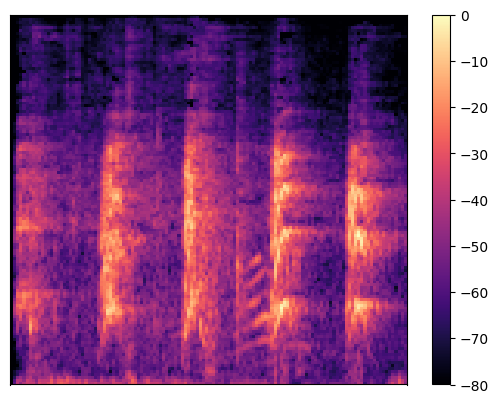

In [4]:
# FEATURE EXTRACTION

# Extract the log-mel spectrogram of the audio file. This spectrogram is forced
# to have a fixed length that is determined by the configuration variable
# NUM_OF_FRAMES. Sequences longer than this quantity are cut, whereas
# sequences shorter than this quantity are padded at the beginning and the
# end with a predefined constant value.

# Configuration variables for log-mel spectrogram computation
WINDOW_LENGTH = 1024  # length of the analysis window in samples
HOP_LENGTH = 512      # number of samples between successive frames (frame period or hop length)
N_MEL = 128           # number of Mel bands to generate
NUM_OF_FRAMES = 128   # fixed duration in frames

# Mel spectrogram computation
melspectrogram = librosa.feature.melspectrogram(y=audio,
                                                sr=sampling_rate,
                                                hop_length=HOP_LENGTH,
                                                win_length=WINDOW_LENGTH,
                                                n_mels=N_MEL)

# Convert the power spectrogram to decibel units (log-mel spectrogram)
melspectrogram_db = librosa.power_to_db(melspectrogram, ref=np.max)

freq_dimension = melspectrogram_db.shape[0]
time_dimension = melspectrogram_db.shape[1]
print('Dimensions of the log-mel spectrogram before the crop/padding process =', freq_dimension, time_dimension)

# Pad or fix the length of spectrogram
if time_dimension != NUM_OF_FRAMES:
    melspectrogram_db = librosa.util.fix_length(melspectrogram_db,
                                                size=NUM_OF_FRAMES,
                                                axis=1,
                                                constant_values=(-80.0, -80.0))

freq_dimension = melspectrogram_db.shape[0]  # number of mel bands
time_dimension = melspectrogram_db.shape[1]  # length of the spectrogram
print('Dimensions of the log-mel spectrogram after the crop/padding process =', freq_dimension, time_dimension)

# Plot the log-mel spectrogram. It corresponds to the category 'dog_bark'
plt.figure()
librosa.display.specshow(melspectrogram_db)
plt.colorbar()



---
### [EXERCISE 1]
---

Answer the following questions:

1. Are we losing any information from the original audio signals by transforming them into log-mel spectrograms and giving the model just that? In other words, is it possible to recover the original audio signal from the log-mel spectrogram alone?

ANSWER:

Yes, we are losing information, so it is not possible to recover the original audio signal from the log-mel spectrogram alone. The information is lost in several steps:

- Power computation: the Fourier transform of each window gives complex numbers (magnitude and phase). By squaring the magnitude to obtain the power spectrogram, the phase is discarded, and it is needed to reconstruct the exact waveform.
- Mel filterbank: the many frequency bins are grouped into only 128 mel bands, so lots of values are mixed together and cannot be separated again.
- Conversion to decibels: the logarithm itself is invertible, but with `ref=np.max` every clip is referenced to its own maximum, so the absolute loudness is lost, and with the default `top_db=80` the components more than 80 dB below the maximum are clipped.
- Fixed length: the signals longer than 128 frames are cut, so the frames outside that window are lost (padding with silence, on the contrary, does not remove information).

2. If Deep Learning is about models learning what features to extract from the raw data, why are we not giving the network the raw audio signals?

ANSWER:

Although the raw audio contains more information than the log-mel spectrogram (as explained in the previous question), that information is not organized in a way that makes learning easy. A 3-second sample has about 66000 values, and the network would have to discover by itself how to extract the frequency content from them, which requires a lot of data and computation; with only 8,732 samples this is difficult. The log-mel spectrogram is a more compact representation (128 × 128 = 16384 values, about four times fewer than the 66000 raw samples) that makes the time-frequency structure explicit, and the mel scale introduces prior knowledge about human hearing. In addition, it can be treated as an image, so CNNs can detect local patterns that are much harder to see in a raw waveform. In short, we accept losing some information in exchange for a representation that is much easier to learn from.

3. Explain the values of the dimensions of the resulting log-mel spectrograms before and after the crop/padding process.

ANSWER:

Before the crop/padding process, the log-mel spectrogram has dimensions 128 × 130. The first value (128) is the number of mel bands, and it is fixed by the parameter `n_mels` of melspectrogram. The second value (1 + 66150 // 512 = **130**, with 66150 = 3 s × 22050) is the number of time frames, and it depends on the length of the audio signal and on the hop length: with a hop length of 512 samples, an audio signal of N samples produces 1 + N // 512 frames.

After the crop/padding process the dimensions are 128 × 128: the first dimension does not change, while the time dimension is cropped to the fixed length NUM_OF_FRAMES = 128, which corresponds to approximately 3 seconds (128 × 512 / 22050 = 2.97 s). This fixed length is needed so that all the spectrograms have the same shape and can be stacked in a batch.

> HINT: Try to find information such as [this](https://arxiv.org/abs/1706.09559) analyzing the first two questions of this exercise.    


---
## 4. LOADING THE PRECOMPUTED FEATURES
---

The script *LabSession2 - Sound Classfication - Preprocessing.ipynb* (available in Aula Global) performs the previously described processes (database download and feature extraction) for the whole database.

After the execution of this script, you should find in your Google Drive directory the following items:

*   A directory called *UrbanSound8k* that contains the speech files in wav format
*   A zip file called *us8k_features.pkl* that contains the corresponding features (log-mel spectrograms)

As at this point, we do not need the audio files, in the following step we will only load the feature file *us8k_features.pkl*.

Also a custom dataset class for the management of this data is created.


In [6]:
# LOADING THE PRECOMPUTED FEATURES
us8k_df = pd.read_pickle("us8k_features.pkl")
us8k_df.head()

,melspectrogram,label,fold
0,"[[-73.21194, -71.38726, -65.72825, -72.96422, ...",3,5
1,"[[-20.675226, -5.9584575, -12.821327, -16.3835...",2,5
2,"[[-21.596546, -18.4566, -6.66292, -12.499052, ...",2,5
3,"[[-14.768795, -14.341509, -16.916325, -15.5090...",2,5
4,"[[-13.062439, -3.303463, -8.647091, -11.555508...",2,5


In [7]:
# CUSTOM DATASET CLASS

DEFAULT_SAMPLE_RATE = 22050

class UrbanSound8kDataset(Dataset):
    def __init__(self, us8k_df, transform=None):
        assert isinstance(us8k_df, pd.DataFrame)
        assert len(us8k_df.columns) == 3

        self.us8k_df = us8k_df
        self.transform = transform

    def __len__(self):
        return len(self.us8k_df)

    def __getitem__(self, index):
        if torch.is_tensor(index):
            index = index.tolist()

        spectrogram, label, fold = self.us8k_df.iloc[index]

        if self.transform is not None:
            spectrogram = self.transform(spectrogram)

        return {'spectrogram': spectrogram, 'label':label}

---
## 5. DATA AUGMENTATION
---

To compensate for the relatively small size of the dataset, two **data augmentation** techniques are used. Data augmentation is performed online by applying the techniques on the input log-mel spectrograms before they are fed to the model. Both techniques are applied with given probabilities, ensuring that the model is rarely trained on the exact same examples. Although this approach is much more time consuming, the effects of overfitting are significantly reduced.

The two main techniques used for the purposes of this lab exercise are:

* **Time Shifting**
* **Background Gaussian Noise**

The following code implements these transformations

In [8]:
# TRANSFORMATIONS

class MyRightShift(object):
    """Shift the image to the right in time."""

    def __init__(self, input_size, width_shift_range, shift_probability=1.0):
        assert isinstance(input_size, (int, tuple))
        assert isinstance(width_shift_range, (int, float))
        assert isinstance(shift_probability, (float))

        if isinstance(input_size, int):
            self.input_size = (input_size, input_size)
        else:
            assert len(input_size) == 2
            self.input_size = input_size

        if isinstance(width_shift_range, int):
            assert width_shift_range > 0
            assert width_shift_range <= self.input_size[1]
            self.width_shift_range = width_shift_range
        else:
            assert width_shift_range > 0.0
            assert width_shift_range <= 1.0
            self.width_shift_range = int(width_shift_range * self.input_size[1])

        assert shift_probability > 0.0 and shift_probability <= 1.0
        self.shift_prob = shift_probability

    def __call__(self, image):
        if np.random.random() > self.shift_prob:
          return image

        # create a new array filled with the min value
        shifted_image= np.full(self.input_size, np.min(image), dtype='float32')

        # randomly choose a start postion
        rand_position = np.random.randint(1, self.width_shift_range)

        # shift the image
        shifted_image[:,rand_position:] = copy.deepcopy(image[:,:-rand_position])

        return shifted_image

class MyAddGaussNoise(object):
    """Add Gaussian noise to the spectrogram image."""

    def __init__(self, input_size, mean=0.0, std=None, add_noise_probability=1.0):
        assert isinstance(input_size, (int, tuple))
        assert isinstance(mean, (int, float))
        assert isinstance(std, (int, float)) or std is None
        assert isinstance(add_noise_probability, (float))


        if isinstance(input_size, int):
            self.input_size = (input_size, input_size)
        else:
            assert len(input_size) == 2
            self.input_size = input_size

        self.mean = mean

        if std is not None:
            assert std > 0.0
            self.std = std
        else:
            self.std = std

        assert add_noise_probability > 0.0 and add_noise_probability <= 1.0
        self.add_noise_prob = add_noise_probability


    def __call__(self, spectrogram):
      if np.random.random() > self.add_noise_prob:
          return spectrogram

      # set some std value
      min_pixel_value = np.min(spectrogram)
      if self.std is None:
        std_factor = 0.03     # factor number
        std = np.abs(min_pixel_value*std_factor)

      # generate a white noise spectrogram
      gauss_mask = np.random.normal(self.mean,
                                    std,
                                    size=self.input_size).astype('float32')

      # add white noise to the sound spectrogram
      noisy_spectrogram = spectrogram + gauss_mask

      return noisy_spectrogram

class MyReshape(object):
    """Reshape the image array."""

    def __init__(self, output_size):
        assert isinstance(output_size, (tuple))

        self.output_size = output_size

    def __call__(self, image):
      return image.reshape(self.output_size)


# build transformation pipelines for data augmentation
train_transforms = transforms.Compose([MyRightShift(input_size=128,
                                                    width_shift_range=13,
                                                    shift_probability=0.9),
                                       MyAddGaussNoise(input_size=128,
                                                       add_noise_probability=0.55),
                                       MyReshape(output_size=(1,128,128))])

test_transforms = transforms.Compose([MyReshape(output_size=(1,128,128))])



---
### [EXERCISE 2]
---

Answer the following questions:

1. Explain the data augmentation mechanism implemented in this class (*MyRightShift* and *MyAddGaussNoise* functions). What would you listen by playing the augmented samples in comparison with the original ones?

ANSWER:

- MyRightShift: it shifts the spectrogram to the right along the time axis, generating delayed versions of the original samples. The shift is done by `shifted_image[:, rand_position:] = image[:, :-rand_position]`: all the time frames except the last `rand_position` ones are copied starting at column `rand_position`, so the content moves to the right and the last frames are lost, while the length stays at 128 frames. `rand_position` is random between 1 and 12 frames (from 0.023 s to 0.28 s, since one frame lasts 512/22050 s). The empty frames on the left are filled with `np.min(image)`, the lowest level of the spectrogram, which corresponds to silence.

- MyAddGaussNoise: it adds white Gaussian noise to the spectrogram. The standard deviation is `std = |min_pixel_value| * 0.03`, meaning 3% of the absolute value of the minimum of the spectrogram. Therefore, the noise is proportional to the range of each sample: the larger the absolute value of the minimum, the noisier the new sample.

If we listened only to the augmented samples, we would hear the original sound starting slightly later, with its last part cut off, and with a faint background hiss. Since each transformation is applied with a probability (0.9 for the shift and 0.55 for the noise), some samples would be only delayed, some only noisy, some both, and a few would remain unchanged.

Data augmentation is needed because the dataset is small. Both transformations are applied online, every time the Dataset returns an example, so the same excerpt looks different in each epoch and the network rarely sees exactly the same sample twice. This reduces the risk of overfitting. The validation and test sets only use MyReshape (test_transforms), because we want to evaluate the model on unmodified data, so that the result reflects the real performance and is reproducible.


2. As you can see, there is another transformation implemented in this class (*MyReshape*). What is the purpose of this transformation?  

ANSWER:

MyReshape does not modify the values of the spectrogram, only its shape. It converts the 128 × 128 input (frequency × time) into (1, 128, 128), adding the channel dimension. Convolutional layers expect each sample as (channels, height, width). In Lab 1 the images had 3 channels because they were RGB, whereas a spectrogram has a single value per time-frequency point, so it has 1 channel.

---
## 6. UTILITY FUNCTIONS
---

There are two additional helper functions:

* *normalize_data*: it normalizes the data to zero mean and unit variance using the corresponding statistics of the training data

* *show_results*: it plots accuracy and loss values obtained during the training process

In [9]:
# UTILITY FUNCTIONS

def normalize_data(train_df, test_df):
    # compute the mean and std (pixel-wise)
    mean = train_df['melspectrogram'].mean()
    std = np.std(np.stack(train_df['melspectrogram']), axis=0)

    # normalize train set
    train_spectrograms = (np.stack(train_df['melspectrogram']) - mean) / std
    train_spectrograms = np.float32(train_spectrograms)
    train_labels = train_df['label'].to_numpy()
    train_folds = train_df['fold'].to_numpy()
    train_df = pd.DataFrame(zip(train_spectrograms, train_labels, train_folds), columns=['melspectrogram', 'label', 'fold'])

    # normalize test set
    test_spectrograms = (np.stack(test_df['melspectrogram']) - mean) / std
    test_spectrograms = np.float32(test_spectrograms)
    test_labels = test_df['label'].to_numpy()
    test_folds = test_df['fold'].to_numpy()
    test_df = pd.DataFrame(zip(test_spectrograms, test_labels, test_folds), columns=['melspectrogram', 'label', 'fold'])

    return train_df, test_df

def show_results(history):
    """Show accuracy and loss graphs for train and test sets."""

    plt.figure(figsize=(15,5))

    plt.subplot(121)
    plt.plot(history['accuracy'])
    plt.plot(history['val_accuracy'])
    plt.grid(linestyle='--')
    plt.ylabel('Accuracy')
    plt.xlabel('Epoch')
    plt.legend(['train', 'validation'], loc='upper left')

    plt.subplot(122)
    plt.plot(history['loss'])
    plt.plot(history['val_loss'])
    plt.grid(linestyle='--')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend(['train', 'validation'], loc='upper left')

    plt.show()

    print('\tMax validation accuracy: %.4f %%' % (np.max(history['val_accuracy']) * 100))
    print('\tMin validation loss: %.5f' % np.min(history['val_loss']))



## 7. CNN-RNN MODEL
---

The general architecture of the CNN-RNN model can be seen in the next Figure.

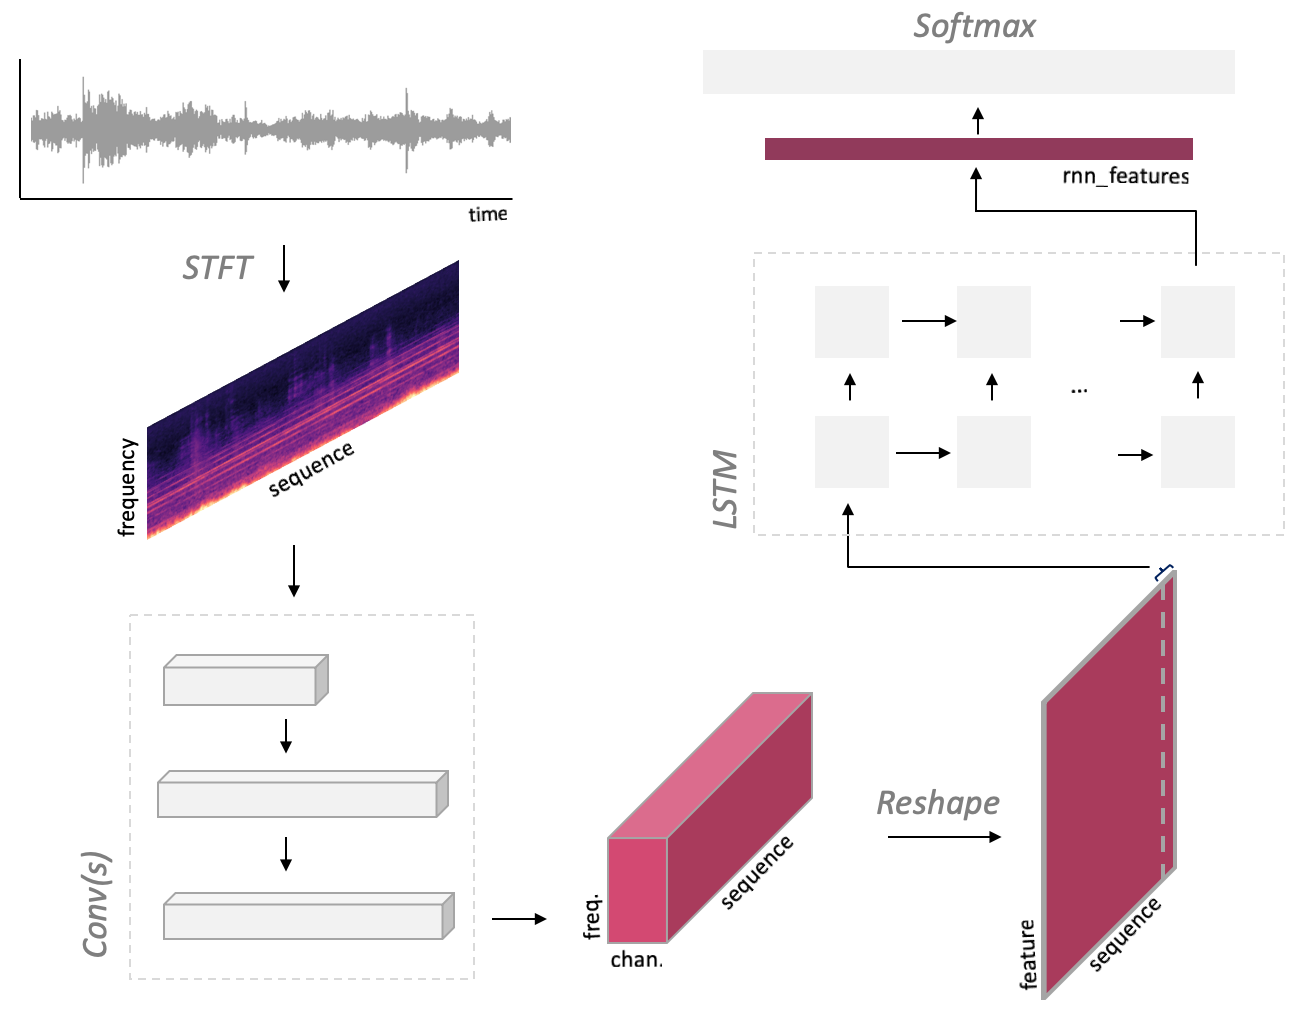

This is a general overview of the complete model:

1. The log-mel spectrogram is passed through a CNN that computes visual features for different time instants. At this point, a time instant is a bunch of columns from the log-mel spectrogram image. In particular, this CNN is composed of three CNN layers, with 32, 64 and 64 filters, respectively.

2. The visual features of each audio excerpt are reshaped and used as a sequence in a LSTM network composed of *hidden_size_rnn* nodes and *num_layers_rnn* layers. Note that LSTM node refers to the number of features in the hidden state.

3. As sound classification is a Many-to-One problem, only the last frames of the output of each of the LSTM nodes are retained.

4. The classifier itself is composed by a linear layer with *num_classes* output units, followed by a softmax activation function.

The following class implements this model together to the **train** and **evaluate** methods.




In [10]:
# CNN-RNN MODEL

class CNN_RNN(nn.Module):
    def __init__(self, hidden_size_rnn, num_layers_rnn, num_classes, device):
        super(CNN_RNN, self).__init__()

        self.convs1 = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=[0, 0]),
            nn.ELU(alpha=1.0),
            nn.MaxPool2d(kernel_size=4, stride=4, padding=0),
            nn.Dropout(p=0.1)
        )

        self.convs2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=[0, 0]),
            nn.ELU(alpha=1.0),
            nn.MaxPool2d(kernel_size=4, stride=4, padding=0),
            nn.Dropout(p=0.1)
        )

        self.convs3 = nn.Sequential(
            nn.Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=[0, 0]),
            nn.ELU(alpha=1.0),
            nn.MaxPool2d(kernel_size=(4, 1), stride=(1, 1), padding=0),
            nn.Dropout(p=0.1)
        )

        self.recur = nn.LSTM(128, hidden_size_rnn, num_layers=num_layers_rnn, batch_first=True)

        self.dense = nn.Sequential(
            nn.Dropout(p=0.3),
            nn.BatchNorm1d(hidden_size_rnn, eps=1e-05, momentum=0.1),
            nn.Linear(in_features=hidden_size_rnn, out_features=num_classes)
        )

        self.criterion = nn.CrossEntropyLoss()
        self.optimizer = optim.Adam(self.parameters(), lr=0.001, eps=1e-07, weight_decay=1e-3)

        self.device = device

    def forward(self, x):

        # input x -> (batch, channel, freq, time)

        # cnn layer-1
        x = self.convs1(x)

        # cnn layer-2
        x = self.convs2(x)

        # cnn layer-3
        x = self.convs3(x)
        # x -> (batch, channel, freq, time)

        # transpose channel and time
        x = x.transpose(1,-1)
        # x -> (batch, time, freq, channel)

        # collapse height and channel
        sizes = x.size()
        x = x.reshape(sizes[0], sizes[1], sizes[2]*sizes[3])
        # xt -> (batch, time, freq*channel)

        # rnn layer
        x,_ = self.recur(x)
        # x -> (batch, time, lstm_out)

        # many-to-one rnn
        x = x[:,-1]
        # x -> (batch, lstm_out)

        # dense output layer
        x = self.dense(x)
        # x -> (batch, num_classes)

        # Softmax activation
        x = F.log_softmax(x, dim=1)
        # x -> (batch, num_classes)

        return x

    def fit(self, train_loader, epochs, val_loader=None):
        history = {'loss':[], 'accuracy':[], 'val_loss':[], 'val_accuracy':[]}

        for epoch in range(epochs):
            self.train()

            print("\nEpoch {}/{}".format(epoch+1, epochs))

            with tqdm(total=len(train_loader), file=sys.stdout) as pbar:
                for step, batch in enumerate(train_loader):
                    X_batch = batch['spectrogram'].to(self.device)
                    y_batch = batch['label'].to(self.device)

                    # zero the parameter gradients
                    self.optimizer.zero_grad()

                    with torch.set_grad_enabled(True):
                        # forward + backward
                        outputs = self.forward(X_batch)
                        batch_loss = self.criterion(outputs, y_batch)
                        batch_loss.backward()

                        # update the parameters
                        self.optimizer.step()

                    pbar.update(1)

            # model evaluation - train data
            train_loss, train_acc = self.evaluate(train_loader)
            print("loss: %.4f - accuracy: %.4f" % (train_loss, train_acc), end='')

            # model evaluation - validation data
            val_loss, val_acc = None, None
            if val_loader is not None:
                val_loss, val_acc = self.evaluate(val_loader)
                print(" - val_loss: %.4f - val_accuracy: %.4f" % (val_loss, val_acc))

            # store the model's training progress
            history['loss'].append(train_loss)
            history['accuracy'].append(train_acc)
            history['val_loss'].append(val_loss)
            history['val_accuracy'].append(val_acc)

        return history

    def evaluate(self, data_loader):
        running_loss = torch.tensor(0.0).to(self.device)
        running_acc = torch.tensor(0.0).to(self.device)

        batch_size = torch.tensor(data_loader.batch_size).to(self.device)
        self.eval()

        with torch.no_grad():
            for step, batch in enumerate(data_loader):
                X_batch = batch['spectrogram'].to(self.device)
                y_batch = batch['label'].to(self.device)

                outputs = self.forward(X_batch)

                # get batch loss
                loss = self.criterion(outputs, y_batch)
                running_loss = running_loss + loss

                # calculate batch accuracy
                predictions = torch.argmax(outputs, dim=1)
                correct_predictions = (predictions == y_batch).float().sum()
                running_acc = running_acc + torch.div(correct_predictions, batch_size)

            loss = running_loss.item() / (step+1)
            accuracy = running_acc.item() / (step+1)

        return loss, accuracy


The following code is useful for understanding the CNN-RNN architecture.

In [11]:
### UNDERSTANDING THE CNN-RNN ARCHITECTURE

hidden_size_rnn = 64
num_layers_rnn = 2
num_classes = 10
device = torch.device("cpu")
model = CNN_RNN(hidden_size_rnn, num_layers_rnn, num_classes, device).to(device)

# Lets go over each step in the forward method of the CNN_RNN model to
# understand the inputs and outputs of each submodule inside it

# generate a batch with a single image to use as model input (just noise
# with the proper dimensions)
# input x -> (batch, channel, freq, time)
x = torch.randn(2, 1, 128, 128)
print(x.shape)

# cnn layer-1
x = model.convs1(x)
# x -> (batch, channel, freq, time)
print(x.shape)

# cnn layer-2
x = model.convs2(x)
# x -> (batch, channel, freq, time)
print(x.shape)

# cnn layer-3
x = model.convs3(x)
# x -> (batch, channel, freq, time)
print(x.shape)

# transpose channel and time
x = x.transpose(1,-1)
# x -> (batch, time, freq, channel)
print(x.shape)

# collapse height and channel
sizes = x.size()
x = x.reshape(sizes[0], sizes[1], sizes[2]*sizes[3])
# xt -> (batch, time, freq*channel)
print(x.shape)

# rnn layer
x,_ = model.recur(x)
# x -> (batch, time, lstm_out)
print(x.shape)

# many-to-one rnn
x = x[:,-1]
# x -> (batch, lstm_out)
print(x.shape)

# dense output layer
x = model.dense(x)
# x -> (batch, num_classes)
print(x.shape)

# Softmax activation
x = F.log_softmax(x, dim=1)
# x -> (batch, num_classes)
print(x.shape)

#print(model)


torch.Size([2, 1, 128, 128])
torch.Size([2, 32, 31, 31])
torch.Size([2, 64, 7, 7])
torch.Size([2, 64, 2, 5])
torch.Size([2, 5, 2, 64])
torch.Size([2, 5, 128])
torch.Size([2, 5, 64])
torch.Size([2, 64])
torch.Size([2, 10])
torch.Size([2, 10])


In [12]:
x = torch.randn(2, 1, 128, 128)

for bloque in (model.convs1, model.convs2, model.convs3):
    for capa in bloque:
        x = capa(x)
        print(type(capa).__name__, x.shape)
    print('---')

Conv2d torch.Size([2, 32, 126, 126])
ELU torch.Size([2, 32, 126, 126])
MaxPool2d torch.Size([2, 32, 31, 31])
Dropout torch.Size([2, 32, 31, 31])
---
Conv2d torch.Size([2, 64, 29, 29])
ELU torch.Size([2, 64, 29, 29])
MaxPool2d torch.Size([2, 64, 7, 7])
Dropout torch.Size([2, 64, 7, 7])
---
Conv2d torch.Size([2, 64, 5, 5])
ELU torch.Size([2, 64, 5, 5])
MaxPool2d torch.Size([2, 64, 2, 5])
Dropout torch.Size([2, 64, 2, 5])
---


---
### [EXERCISE 3]
---
After analyzing the architecture of the CNN-RNN model and the previous cell code, answer the following questions:

1. Explain the dimensions of the data at the output of the last CNN layer.

ANSWER:

The output of the last CNN layer has shape [2, 64, 2, 5], which corresponds to (batch, channels, freq, time):

- 2 is the batch size (the two random examples used as input).
- 64 is the number of channels, the number of filters of the last convolutional layer.
- 2 is the size of the frequency axis. It has been progressively reduced by the convolutions (no padding, kernel 3) and the poolings: 128 → 126 → 31 → 29 → 7 → 5 → 2. The last max-pooling has kernel (4, 1), so it also compresses the frequency axis (5 → 2).
- 5 is the size of the time axis: 128 → 126 → 31 → 29 → 7 → 5 → 5. The last pooling has kernel size 1 in time, so it does not reduce it. Each of these 5 positions is a “time instant” that summarizes a group of consecutive columns of the original log-mel spectrogram.

In this way, the CNN converts the spectrogram into a short sequence of 5 time steps, each one described by 64 × 2 = 128 features, which is what the LSTM receives.

2. What is the role of the recursive layer inside the CNN-RNN class?

ANSWER:

The convolutional layers extract local time-frequency patterns, but they process each region independently. The recurrent layer processes the sequence of 5 feature vectors one time step at a time and keeps a hidden state that acts as a memory, so the output at each step depends on the current input and also on the previous ones. In this model it receives a tensor [2, 5, 128] and returns [2, 5, 64]. This allows the network to model how the sound evolves in time (for example, the rising and falling tone of a siren, or the difference between a short gunshot and a continuous engine), which a single CNN output cannot capture.

3. Why does the first argument of the LSTM layer have to be 128?

ANSWER:

The first argument of `nn.LSTM` is the number of input features at each time step. After the CNN, the tensor is [batch, 64 channels, 2 freq, 5 time]; the transpose puts time in the second position ([2, 5, 2, 64]) and the reshape merges the frequency and channel axes: 2 × 64 = 128. So, each of the 5 time steps is a vector of 128 values, and the LSTM must be built with `input_size = 128`. If we changed the number of filters of the last convolution, the pooling or the size of the input spectrogram, this value would change and the LSTM would have to be modified accordingly.

4. Why does the output of the "Many-to-One" step produce a 2-dimensional vector?

ANSWER:

The LSTM output has shape `[batch, time, 64] = [2, 5, 64]`. In a many-to-one problem we need a single prediction for each audio, not one per time step, so we keep only the output of the last time step with `x[:, -1]`. This removes the time axis and leaves a 2-dimensional tensor `[batch, features] = [2, 64]`. The last output is chosen because, through its hidden state, it has seen the whole sequence, so it summarizes all the information of the excerpt.

5. What is the role of the softmax activation function?

ANSWER:

The final linear layer returns 10 real scores (one per class) that can be any positive or negative number. The softmax converts them into a probability distribution: all the values are positive and they sum to 1, so each one can be interpreted as the probability that the excerpt belongs to that class, and the predicted class is the one with the highest probability (argmax).

---
## 8. SPLITTING AND NORMALIZING THE DATA
---

The original database is divided into 10 different folds. In this lab exercise, we are going to use folds 3-10 for training, fold 1 for testing and fold 2 for validation.

Once the division into training, validation and testing sets is performed, the data is normalized to mean zero and variance unity with respect to the training data.

In [13]:
# SPLITTING AND NORMALIZING THE DATA

fold_k = 1
dataset_df = us8k_df

# split the data
train_df = dataset_df[dataset_df['fold'] > (fold_k+1)]
val_df = dataset_df[dataset_df['fold'] == fold_k+1]
test_df = dataset_df[dataset_df['fold'] == fold_k]

# normalize the data
train_df_norm, val_df_norm = normalize_data(train_df, val_df)
train_df_norm, test_df_norm = normalize_data(train_df, test_df)

---
## 9. TRAINING AND TESTING THE SYSTEM
---

The next code cell contains all the necessary to train and test the sound classification system.


Epoch 1/15
100%|██████████| 218/218 [00:07<00:00, 30.41it/s]
loss: 1.3489 - accuracy: 0.4989 - val_loss: 1.5120 - val_accuracy: 0.3996

Epoch 2/15
100%|██████████| 218/218 [00:04<00:00, 49.42it/s]
loss: 0.8999 - accuracy: 0.6855 - val_loss: 1.2022 - val_accuracy: 0.6060

Epoch 3/15
100%|██████████| 218/218 [00:04<00:00, 46.02it/s]
loss: 0.5470 - accuracy: 0.8159 - val_loss: 0.9619 - val_accuracy: 0.6339

Epoch 4/15
100%|██████████| 218/218 [00:05<00:00, 38.98it/s]
loss: 0.4432 - accuracy: 0.8568 - val_loss: 0.8658 - val_accuracy: 0.6763

Epoch 5/15
100%|██████████| 218/218 [00:04<00:00, 48.77it/s]
loss: 0.4296 - accuracy: 0.8588 - val_loss: 0.8566 - val_accuracy: 0.6842

Epoch 6/15
100%|██████████| 218/218 [00:05<00:00, 40.47it/s]
loss: 0.3066 - accuracy: 0.9042 - val_loss: 0.8498 - val_accuracy: 0.7132

Epoch 7/15
100%|██████████| 218/218 [00:04<00:00, 45.09it/s]
loss: 0.3810 - accuracy: 0.8706 - val_loss: 1.0483 - val_accuracy: 0.6138

Epoch 8/15
100%|██████████| 218/218 [00:04<00:0

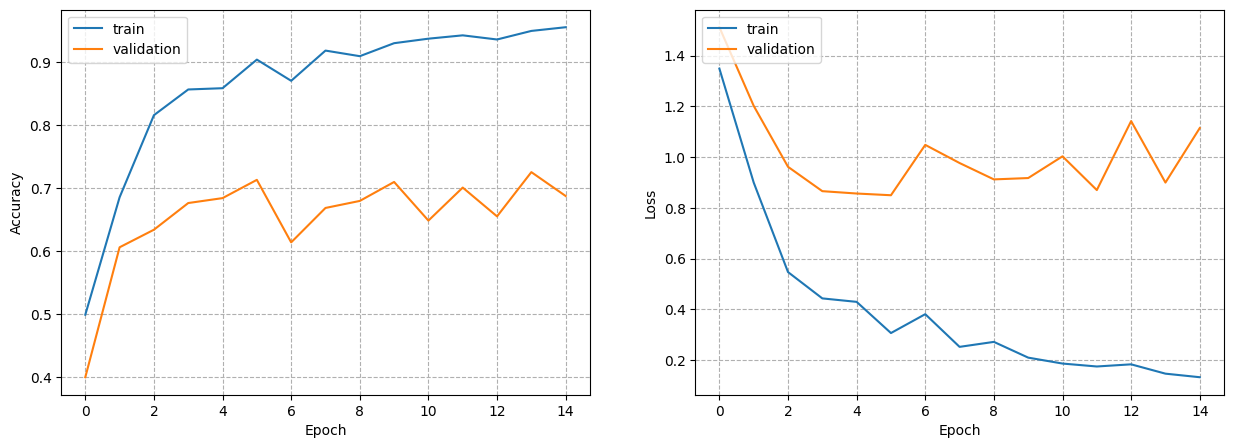

	Max validation accuracy: 72.5446 %
	Min validation loss: 0.84980


In [14]:
# TRAINING THE SYSTEM

# training configuration
epochs = 15
batch_size = 32
num_of_workers = 0

# model configuration
hidden_size_rnn = 64
num_layers_rnn = 2
num_classes = 10

# determine if the system supports CUDA
if torch.cuda.is_available():
  device = torch.device("cuda:0")
else:
  device = torch.device("cpu")

# init model
model = CNN_RNN(hidden_size_rnn, num_layers_rnn, num_classes, device).to(device)

# init train data loader
train_ds = UrbanSound8kDataset(train_df_norm, transform=train_transforms)
train_loader = DataLoader(train_ds,
                          batch_size = batch_size,
                          shuffle = True,
                          pin_memory = True,
                          num_workers = num_of_workers)

# init valid data loader
val_ds = UrbanSound8kDataset(val_df_norm, transform=test_transforms)
val_loader = DataLoader(val_ds,
                        batch_size = batch_size,
                        shuffle = False,
                        pin_memory = True,
                        num_workers = num_of_workers)

# train the model
start_time = datetime.now()
history = model.fit(train_loader, epochs=epochs, val_loader=val_loader)
end_time = datetime.now() - start_time
print("\nTraining completed in time: {}".format(end_time))

# show the results
show_results(history)


In [15]:
# TESTING THE SYSTEM

# init test data loader
test_ds = UrbanSound8kDataset(test_df_norm, transform=test_transforms)
test_loader = DataLoader(test_ds,
                        batch_size = batch_size,
                        shuffle = False,
                        pin_memory = True,
                        num_workers = num_of_workers)

# Test accuracy
score = model.evaluate(test_loader)
print("Test accuracy: %.4f%%" % (100 * score[1]))


Test accuracy: 65.8482%


---
### [EXERCISE 4]
---
           
1.  Modify the "Many-to-One" step of the CNN-RNN architecture for incorporating a Mean-Pooling mechanism.

ANSWER:

The “many-to-one” step `x = x[:, -1]` (which keeps only the last time step of the LSTM output) has been replaced by `x = torch.mean(x, dim=1)`, which averages the LSTM outputs over the 5 time steps. The shape is still [batch, 64], so the dense layer is not modified.

2. Train and test the system with this modification. Does the model performance
improve by using the Mean-Pooling mechanism? Why do you think this happens?

ANSWER:

With mean-pooling, the test accuracy goes from 65.85% to 68.64%, but the validation metrics do not improve (best validation accuracy 70.42% vs. 72.54%, minimum validation loss 0.961 vs. 0.850). Moreover, the results of the same model change from one run to another: in a previous run of the original model (not shown in this notebook) the best validation accuracy was 67.30% instead of 72.54%, a variation of about 5 points, although its test accuracy only changed from 66.18% to 65.85%. Since I only have one run of the mean-pooling model, I consider the improvement in test accuracy suggestive but not conclusive.

A possible explanation for the (small) improvement is that, with the last time step, the whole decision depends on the final part of the excerpt, which for short sounds corresponds to the padding with silence (−80 dB), and the LSTM has to carry the information of the previous steps up to that point. With mean-pooling, all the time steps contribute directly to the decision, and the gradient reaches all of them directly, so the prediction depends less on a single step. On the other hand, averaging has a drawback: if a short event (a gunshot, a dog bark) occupies only one or two of the 5 steps and the rest is silence or background noise, the average dilutes its contribution. This hypothesis would have to be confirmed with more runs of each model.

In [16]:
class CNN_RNN_Mean(CNN_RNN):
    def forward(self, x):
        x = self.convs1(x)
        x = self.convs2(x)
        x = self.convs3(x)
        x = x.transpose(1, -1)
        sizes = x.size()
        x = x.reshape(sizes[0], sizes[1], sizes[2]*sizes[3])
        x, _ = self.recur(x)
        x = torch.mean(x, dim=1)
        x = self.dense(x)
        x = F.log_softmax(x, dim=1)
        return x

In [17]:
m = CNN_RNN_Mean(64, 2, 10, torch.device('cpu'))
print(m(torch.randn(2, 1, 128, 128)).shape)

torch.Size([2, 10])



Epoch 1/15
100%|██████████| 218/218 [00:05<00:00, 38.42it/s]
loss: 1.2179 - accuracy: 0.5862 - val_loss: 1.3573 - val_accuracy: 0.5022

Epoch 2/15
100%|██████████| 218/218 [00:04<00:00, 49.19it/s]
loss: 0.8173 - accuracy: 0.7091 - val_loss: 1.0588 - val_accuracy: 0.6228

Epoch 3/15
100%|██████████| 218/218 [00:05<00:00, 40.49it/s]
loss: 0.8046 - accuracy: 0.7282 - val_loss: 1.1635 - val_accuracy: 0.6295

Epoch 4/15
100%|██████████| 218/218 [00:04<00:00, 45.10it/s]
loss: 0.7788 - accuracy: 0.7314 - val_loss: 1.1596 - val_accuracy: 0.5915

Epoch 5/15
100%|██████████| 218/218 [00:04<00:00, 48.77it/s]
loss: 0.4729 - accuracy: 0.8304 - val_loss: 1.0804 - val_accuracy: 0.6451

Epoch 6/15
100%|██████████| 218/218 [00:05<00:00, 37.74it/s]
loss: 0.3452 - accuracy: 0.8846 - val_loss: 0.9852 - val_accuracy: 0.6741

Epoch 7/15
100%|██████████| 218/218 [00:04<00:00, 48.66it/s]
loss: 0.4007 - accuracy: 0.8754 - val_loss: 0.9960 - val_accuracy: 0.6875

Epoch 8/15
100%|██████████| 218/218 [00:04<00:0

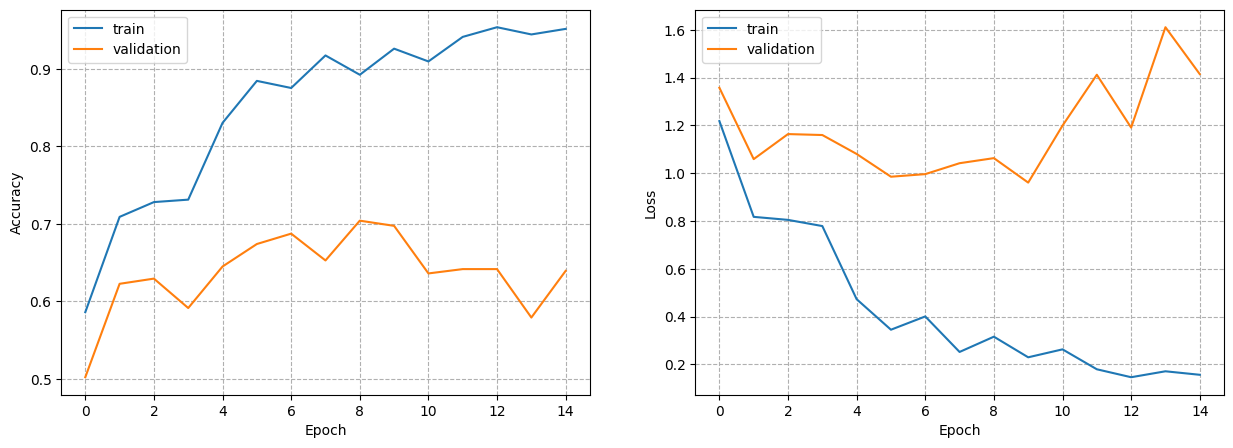

	Max validation accuracy: 70.4241 %
	Min validation loss: 0.96058


In [18]:
# TRAINING THE SYSTEM

# training configuration
epochs = 15
batch_size = 32
num_of_workers = 0

# model configuration
hidden_size_rnn = 64
num_layers_rnn = 2
num_classes = 10

# determine if the system supports CUDA
if torch.cuda.is_available():
  device = torch.device("cuda:0")
else:
  device = torch.device("cpu")

# init model
model_mean = CNN_RNN_Mean(hidden_size_rnn, num_layers_rnn, num_classes, device).to(device)

# init train data loader
train_ds = UrbanSound8kDataset(train_df_norm, transform=train_transforms)
train_loader = DataLoader(train_ds,
                          batch_size = batch_size,
                          shuffle = True,
                          pin_memory = True,
                          num_workers = num_of_workers)

# init valid data loader
val_ds = UrbanSound8kDataset(val_df_norm, transform=test_transforms)
val_loader = DataLoader(val_ds,
                        batch_size = batch_size,
                        shuffle = False,
                        pin_memory = True,
                        num_workers = num_of_workers)

# train the model
start_time = datetime.now()
history_mean = model_mean.fit(train_loader, epochs=epochs, val_loader=val_loader)
end_time = datetime.now() - start_time
print("\nTraining completed in time: {}".format(end_time))

# show the results
show_results(history_mean)


In [19]:
# TESTING THE SYSTEM

# init test data loader
test_ds = UrbanSound8kDataset(test_df_norm, transform=test_transforms)
test_loader = DataLoader(test_ds,
                        batch_size = batch_size,
                        shuffle = False,
                        pin_memory = True,
                        num_workers = num_of_workers)

# Test accuracy
score_mean = model_mean.evaluate(test_loader)
print("Test accuracy: %.4f%%" % (100 * score_mean[1]))

Test accuracy: 68.6384%


---
### [EXERCISE 5]
---
           
1.  In some occassions, it is possible to get an extra boost in performance by allowing the recursive layer to use both, past and future samples for the present predictions. Take a look at the "bidirectional" option in the LSTM layer, and change your code to use it.

ANSWER:

The LSTM has been made bidirectional by setting bidirectional=True in nn.LSTM (class CNN_BiRNN). A bidirectional LSTM consists of two LSTMs that process the sequence in opposite directions, and their outputs are concatenated, so the output size per time step doubles from 64 to 2 × 64 = 128. For this reason, the input size of the BatchNorm1d and Linear layers of the dense block had to be changed to 2*hidden_size_rnn.


2. Train and test the system with this modification. Does the model performance
improve by using bidirectional LSTMs?

ANSWER:

The bidirectional LSTM does not improve the performance of the model. The test accuracy is 62.61%, lower than that of the original model (65.85%) and of the mean-pooling model (68.64%), and the validation metrics are not better either (best validation accuracy 68.86% vs. 72.54% for the original model; minimum validation loss 0.873 vs. 0.850). The training curves show a similar overfitting (training accuracy around 95%) and an unstable validation. Since I only have one run of this model, the result is not conclusive, but in the two runs of the original model the test accuracy changed only by 0.3 points (66.18% and 65.85%), so a difference of about 3 points suggests that the bidirectional model is slightly worse, and in any case there is no evidence of improvement.

A possible explanation is related to the many-to-one step, which keeps only the last time step of the LSTM output (x[:, -1]). In a bidirectional LSTM, the output at each time step is the concatenation of the forward and the backward outputs. At the last time step, the forward half has already processed the whole sequence, but the backward half, which reads the sequence from the end to the beginning, has processed only the last time step. Therefore, half of the 128 features that reach the classifier carries almost no context, and the main advantage of the bidirectional layer (using future information at every time step) is not exploited. A second possible reason is that the model has more parameters (a double LSTM and a larger dense layer) and the dataset is small, so it may overfit more easily. These hypotheses would have to be confirmed with more runs and with other ways of combining the outputs, for example applying the mean-pooling of the previous exercise on the bidirectional output.

> HINT: Bidirectional recursive layers in Pytorch are implemented as two individual layers, each of them looking at the input data in reverse order from each other. Both individual outputs are concatenated into a final tensor. Thus, the dimension of the output gets doubled with respect to a non bidirectional LSTM. Note this fact has influence on the input size of the next dense layer.



In [20]:
class CNN_BiRNN(CNN_RNN):
    def __init__(self, hidden_size_rnn, num_layers_rnn, num_classes, device):
        super().__init__(hidden_size_rnn, num_layers_rnn, num_classes, device)

        # LSTM bidireccional
        self.recur = nn.LSTM(128, hidden_size_rnn, num_layers=num_layers_rnn,
                             batch_first=True, bidirectional=True)

        # la salida de la LSTM ahora tiene 2*hidden_size_rnn valores por paso
        self.dense = nn.Sequential(
            nn.Dropout(p=0.3),
            nn.BatchNorm1d(2*hidden_size_rnn, eps=1e-05, momentum=0.1),
            nn.Linear(in_features=2*hidden_size_rnn, out_features=num_classes)
        )

        # recrear el optimizador con los parámetros de las capas nuevas
        self.optimizer = optim.Adam(self.parameters(), lr=0.001, eps=1e-07, weight_decay=1e-3)

In [21]:
m = CNN_BiRNN(64, 2, 10, torch.device('cpu'))
print(m(torch.randn(2, 1, 128, 128)).shape)      # debe salir torch.Size([2, 10])
print(m.recur(torch.randn(2, 5, 128))[0].shape)  # debe salir torch.Size([2, 5, 128])

torch.Size([2, 10])
torch.Size([2, 5, 128])



Epoch 1/15
100%|██████████| 218/218 [00:04<00:00, 44.36it/s]
loss: 1.5601 - accuracy: 0.4903 - val_loss: 1.5704 - val_accuracy: 0.4163

Epoch 2/15
100%|██████████| 218/218 [00:06<00:00, 32.83it/s]
loss: 1.1560 - accuracy: 0.6352 - val_loss: 1.3165 - val_accuracy: 0.5279

Epoch 3/15
100%|██████████| 218/218 [00:05<00:00, 40.86it/s]
loss: 0.6402 - accuracy: 0.7709 - val_loss: 0.9631 - val_accuracy: 0.6406

Epoch 4/15
100%|██████████| 218/218 [00:05<00:00, 43.34it/s]
loss: 0.5361 - accuracy: 0.8194 - val_loss: 0.8731 - val_accuracy: 0.6797

Epoch 5/15
100%|██████████| 218/218 [00:05<00:00, 40.50it/s]
loss: 0.4196 - accuracy: 0.8501 - val_loss: 1.0177 - val_accuracy: 0.6451

Epoch 6/15
100%|██████████| 218/218 [00:04<00:00, 48.02it/s]
loss: 0.5105 - accuracy: 0.8284 - val_loss: 0.9521 - val_accuracy: 0.6596

Epoch 7/15
100%|██████████| 218/218 [00:05<00:00, 37.64it/s]
loss: 0.3380 - accuracy: 0.8882 - val_loss: 1.2001 - val_accuracy: 0.6239

Epoch 8/15
100%|██████████| 218/218 [00:04<00:0

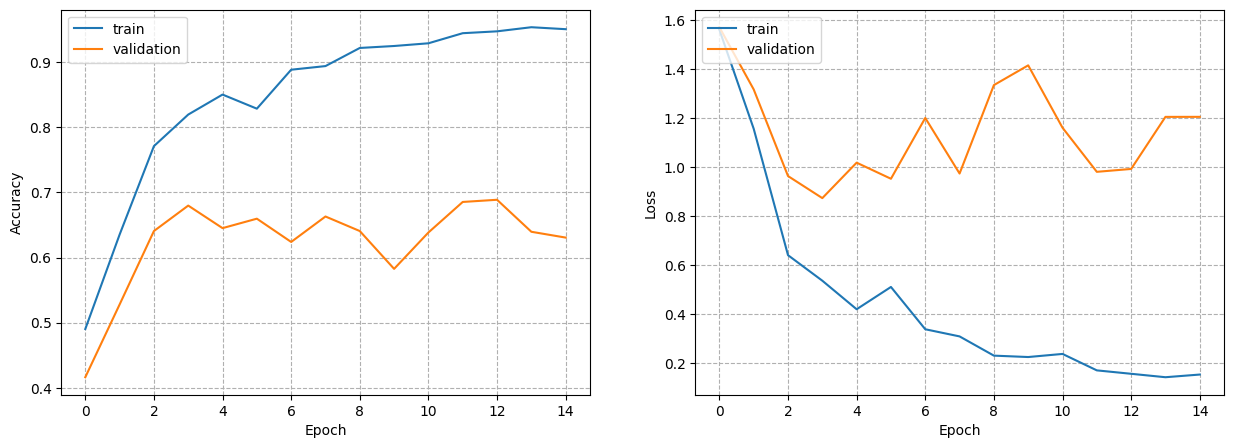

	Max validation accuracy: 68.8616 %
	Min validation loss: 0.87306


In [22]:
# TRAINING THE SYSTEM

# training configuration
epochs = 15
batch_size = 32
num_of_workers = 0

# model configuration
hidden_size_rnn = 64
num_layers_rnn = 2
num_classes = 10

# determine if the system supports CUDA
if torch.cuda.is_available():
  device = torch.device("cuda:0")
else:
  device = torch.device("cpu")

# init model
model_bi = CNN_BiRNN(hidden_size_rnn, num_layers_rnn, num_classes, device).to(device)

# init train data loader
train_ds = UrbanSound8kDataset(train_df_norm, transform=train_transforms)
train_loader = DataLoader(train_ds,
                          batch_size = batch_size,
                          shuffle = True,
                          pin_memory = True,
                          num_workers = num_of_workers)

# init valid data loader
val_ds = UrbanSound8kDataset(val_df_norm, transform=test_transforms)
val_loader = DataLoader(val_ds,
                        batch_size = batch_size,
                        shuffle = False,
                        pin_memory = True,
                        num_workers = num_of_workers)

# train the model
start_time = datetime.now()
history_bi = model_bi.fit(train_loader, epochs=epochs, val_loader=val_loader)
end_time = datetime.now() - start_time
print("\nTraining completed in time: {}".format(end_time))

# show the results
show_results(history_bi)


In [23]:
score_bi = model_bi.evaluate(test_loader)
print("Test accuracy: %.4f%%" % (100 * score_bi[1]))

Test accuracy: 62.6116%
